# CityPulse: Mumbai 2015–2025
Reproducible historical gridded-reanalysis analysis; not station observations or a flood forecast. Run from this notebook directory. See docs/REPORT.md for findings and limits.

In [1]:
from pathlib import Path
import pandas as pd
import json
from pipeline import clean, thresholds, signals, evaluate, summarize, ROOT
raw=json.loads((ROOT/'data/raw/nasa_power_mumbai_2015_2025.json').read_text())
d=clean(raw)
assert len(d)==4018 and not d.isna().any().any()
d.head()

            tmax_c  tmin_c  tmean_c  rain_mm
date                                        
2015-01-01   27.83   17.52    21.87     0.10
2015-01-02   28.01   16.40    21.64     0.01
2015-01-03   28.10   16.99    21.80     0.02
2015-01-04   31.33   16.68    23.61     0.00
2015-01-05   31.79   17.90    23.87     0.00


## Coverage and integrity
Fill values become missing. No imputation. Source metadata and hash are preserved.

In [2]:
d.describe()
print(d.isna().sum())
print(raw['header'])

tmax_c     0
tmin_c     0
tmean_c    0
rain_mm    0
dtype: int64
{'title': 'NASA/POWER Source Native Resolution Daily Data', 'api': {'version': 'v2.10.1', 'name': 'POWER Daily API'}, 'sources': ['MERRA2', 'POWER'], 'fill_value': -999.0, 'time_standard': 'LST', 'start': '20150101', 'end': '20251231'}


## Fixed training-only historical signals
All thresholds fit only 2015–2021; validation/test never enter them.

In [3]:
t=thresholds(d)
s=signals(d,t)
print(t)
annual,monthly,findings=summarize(s)
for f in findings: print(f['title'],f['text'])

{'heat_p90_c': 39.27, 'heat_p95_c': 40.193999999999996, 'rain_wet_p95_mm': 73.65949999999997, 'rain_wet_p99_mm': 117.89959999999999, 'fit_start': '2015-01-01', 'fit_end': '2021-12-31', 'wet_day_definition': 'rain_mm >= 1.0; analytical convention, not an official warning'}
Seasonal heat peak Month 4 has the highest 2015–2025 mean daily maximum temperature: 39.61 °C. This describes the selected grid cell, not personal heat exposure.
Rainfall seasonality June–September contributes 91.3% of total precipitation in the 2015–2025 grid-cell series. Drainage maintenance planning can use this seasonal concentration, not individual flood predictions.
Wettest study year 2019 has the largest annual precipitation total in this dataset: 3387.3 mm. This is not evidence of flood occurrence.


<notebook>:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown

<notebook>:3: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown

<notebook>:4: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



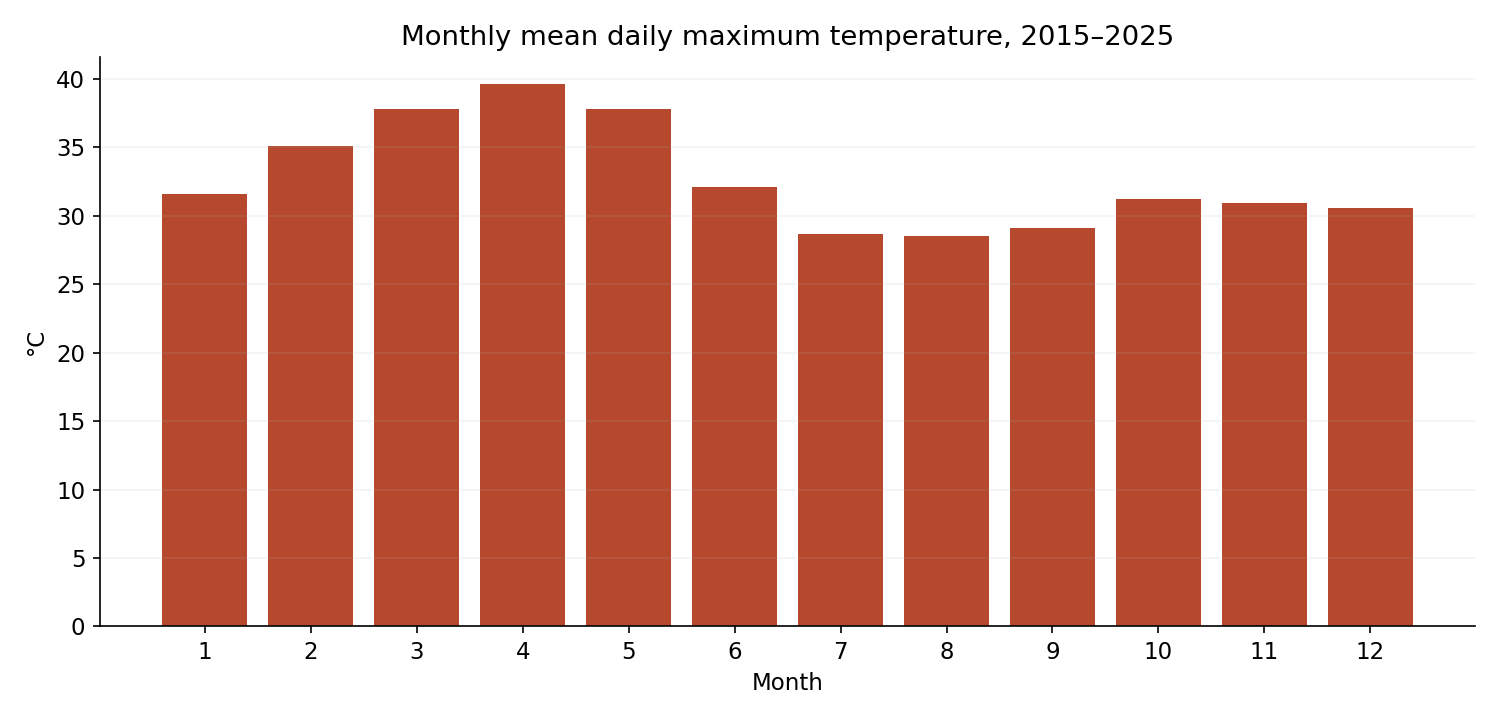

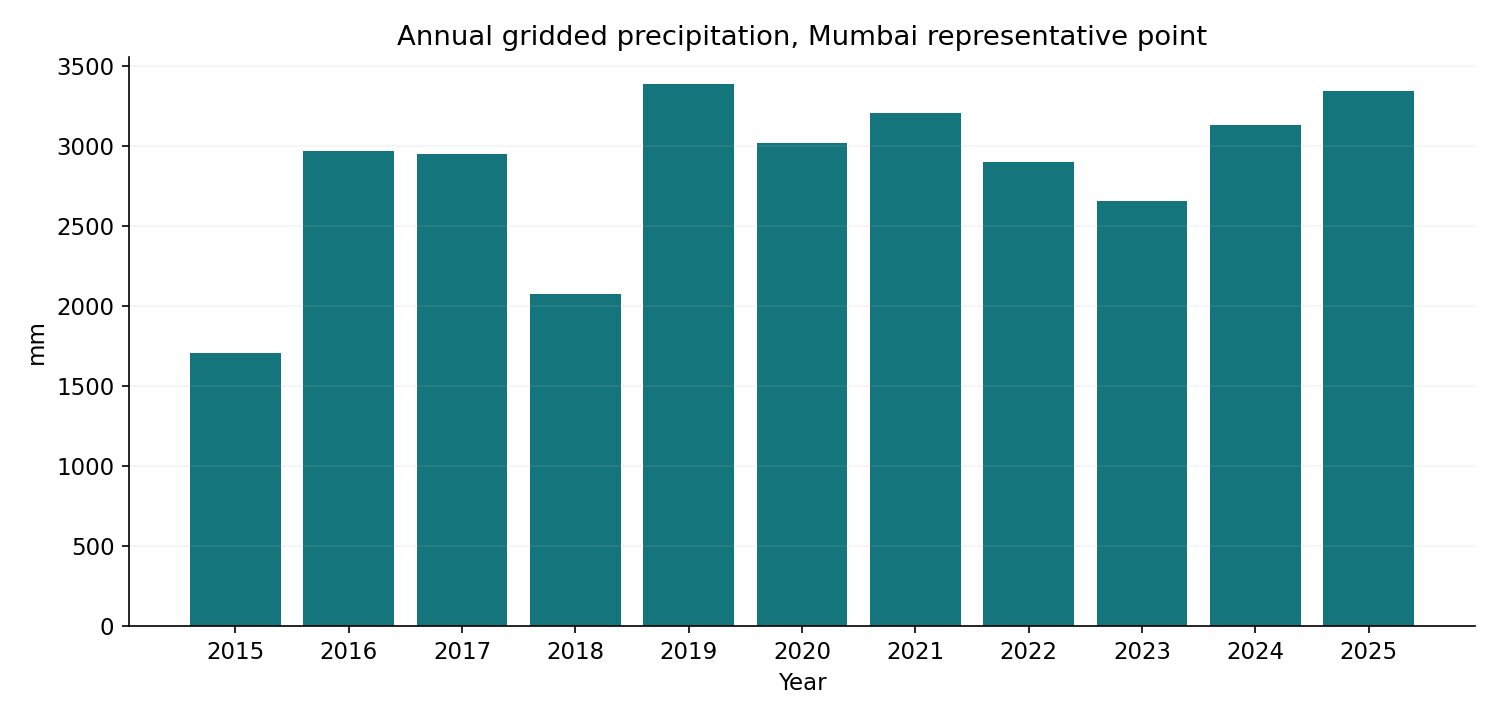

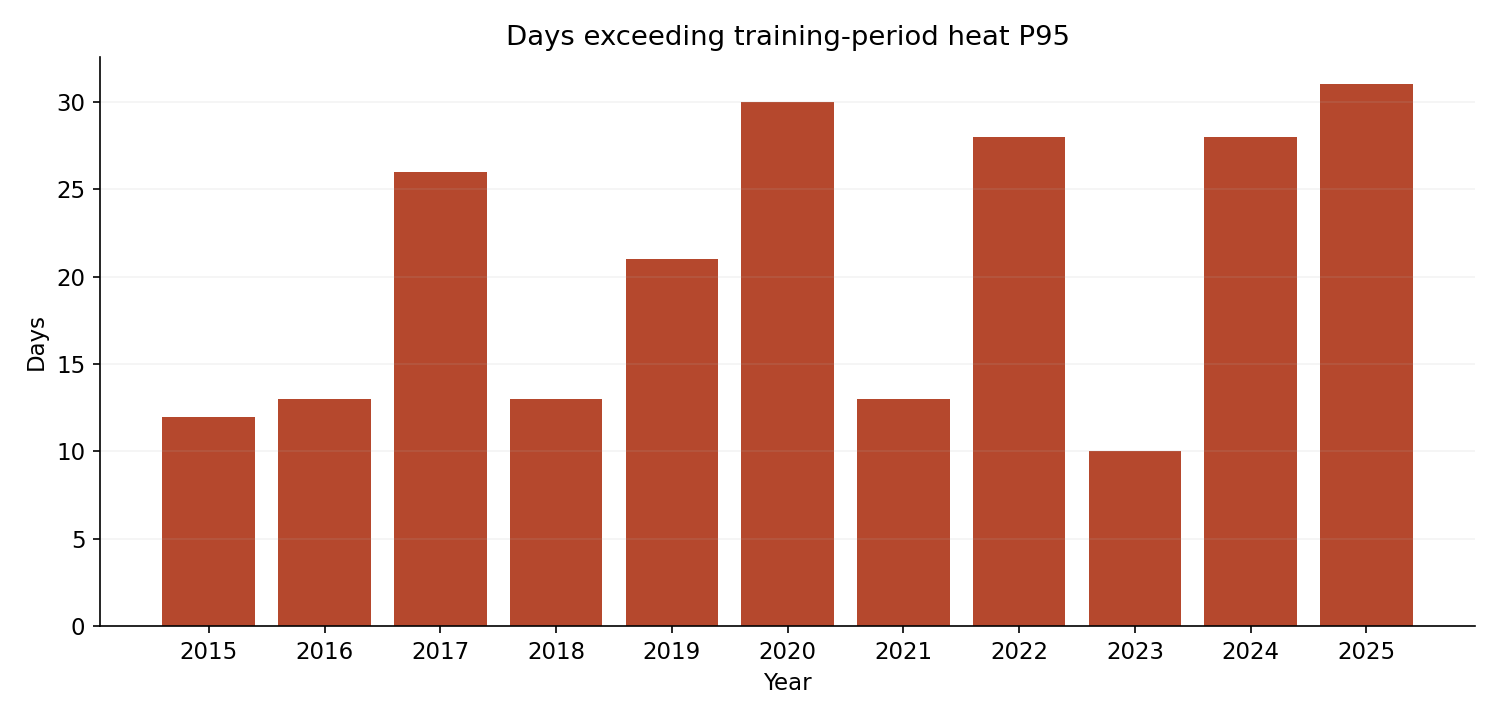

In [4]:
import matplotlib.pyplot as plt
monthly.mean_tmax_c.plot.bar(title='Monthly mean daily Tmax (degrees C)');plt.show()
annual.rain_total_mm.plot.bar(title='Annual precipitation total (mm)');plt.show()
annual.heat_high_days.plot.bar(title='High heat signal days');plt.show()

## Chronological baseline experiment
Train 2015–2021; validation 2022–2023; test 2024–2025. Persistence uses previous day. Compare within-variable MAE/RMSE; Brier evaluates event probabilities. This is not independent flood/health validation or an operational next-day forecasting service.

In [5]:
evaluation=evaluate(s)
evaluation

        split variable               method  ...    recall        f1  accuracy
0  validation   tmax_c          persistence  ...  0.710526  0.710526  0.969863
1  validation   tmax_c  seasonal_train_mean  ...  0.000000  0.000000  0.947945
2        test   tmax_c          persistence  ...  0.593220  0.593220  0.934337
3        test   tmax_c  seasonal_train_mean  ...  0.000000  0.000000  0.919289
4  validation  rain_mm          persistence  ...  0.461538  0.461538  0.980822
5  validation  rain_mm  seasonal_train_mean  ...  0.000000  0.000000  0.982192
6        test  rain_mm          persistence  ...  0.153846  0.153846  0.969904
7        test  rain_mm  seasonal_train_mean  ...  0.000000  0.000000  0.982216

[8 rows x 17 columns]


## Interpretation and limitations
No causal attribution, city-wide station record, neighborhood exposure or flood-occurrence claim. Precipitation and temperature alone do not identify real-world damages. Threshold rules are descriptive and not official advisories. See docs/REPORT.md and README.md for recommendations and data attribution.